<div align="center">

# Proyecto Integrador de Ciencia de Datos
## Fase 4 (actividades 7, 8 y 9) · Comunicación y entrega final

### ¿Qué tecnología renovable presenta el mejor desempeño integral a escala de planta y qué factores técnicos y geográficos explican las diferencias entre plantas?

**Carolina Rodríguez Chacón** · carodriguez03@unisalle.edu.co<br>
Maestría en Inteligencia Artificial · Facultad de Ingeniería · **Universidad de La Salle**<br>
**Curso:** 2026-2_Ciencia de Datos_G2 · **Docente:** Fabián Camilo Castro Riveros<br>
**Fecha de elaboración:** noviembre de 2026

</div>

---

### Qué hace este cuaderno

Las fases 1 a 3 tienen sus propios cuadernos en esta misma carpeta. Este cuaderno contiene **solo lo nuevo de la Fase 4**:

| Sección | Contenido |
|---|---|
| 1 | Verifica que los datos, los modelos y el multicriterio son exactamente los de la Fase 3 |
| 2 | Agrega el recurso de cada país (NASA POWER) y su rendimiento real (IRENA), y valida si el recurso predice el rendimiento |
| 3 | Recomienda una renovable por país y mide qué tan robusta es esa recomendación |
| 4 | Escenario hipotético de geotérmica con ondas milimétricas: qué pasaría, cómo se comportaría y cuál sería su potencial |
| 5 | Genera las tablas del tablero y las figuras del informe final |

El tablero interactivo está en `dashboard/app.py` y usa las tablas que produce este cuaderno.

# 1. Verificación del punto de partida

In [1]:
import json
import subprocess
import sys
import warnings
from pathlib import Path

RAIZ = Path("..").resolve() if Path("../src").exists() else Path(".").resolve()
if not (RAIZ / "src").exists():                     # Google Colab: se trae el repositorio público
    URL_REPOSITORIO = "https://github.com/codemotozu/energias-renovables-ml-multicriterio-streamlit"
    subprocess.run(["git", "clone", "--depth", "1", URL_REPOSITORIO, "repo"], check=True)
    RAIZ = Path("repo").resolve()
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "scikit-learn==1.7.0", "joblib==1.5.1", "kaleido==0.2.1"], check=True)   # misma versión que entrenó los modelos
sys.path.insert(0, str(RAIZ / "src"))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from IPython.display import Markdown, display
from scipy import stats

from renovables import geotermica as geo, multicriterio as mc, paises as pa, saltos as sa
from renovables.artefactos import VARS_CLUSTER, construir
from renovables.datos import PREDICTORES, SEMILLA, TECS, cargar_gppd, preparar_modelado
from renovables.trayectoria import calcular_trayectoria, leer_serie_mundial

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 180)
PROC, FIG = RAIZ / "data" / "processed", RAIZ / "reports" / "figuras"
FIG.mkdir(parents=True, exist_ok=True)
TEC_COLOR = {"Solar": "#eda100", "Eólica": "#1baf7a", "Hidroeléctrica": "#2a78d6", "Geotérmica": "#e34948", "Biomasa": "#008300"}
TINTA, TINTA2, GRIS, RETICULA = "#0b0b0b", "#52514e", "#c3c2b7", "#e1e0d9"
plt.rcParams.update({"font.family": "sans-serif", "font.sans-serif": ["Arial", "DejaVu Sans"], "font.size": 7, "axes.labelsize": 7,
                     "xtick.labelsize": 6.5, "ytick.labelsize": 6.5, "legend.fontsize": 6.5, "axes.edgecolor": GRIS, "axes.labelcolor": TINTA,
                     "xtick.color": TINTA2, "ytick.color": TINTA2, "axes.titlesize": 7, "axes.grid": True, "grid.color": RETICULA, "grid.linewidth": 0.5,
                     "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False, "figure.facecolor": "white", "axes.facecolor": "white",
                     "savefig.facecolor": "white", "lines.linewidth": 1.2, "figure.dpi": 150, "legend.frameon": False})
print("Carpeta del proyecto:", RAIZ.name)

Carpeta del proyecto: Fase_4_Actividades_7_8_y_9_Ciencia_de_Datos


In [2]:
# Datos, partición y modelos: deben ser exactamente los de la Fase 3
gppd = cargar_gppd(RAIZ / "data" / "raw" / "gppd_v1_3" / "global_power_plant_database.csv")   # verifica la huella SHA-256
df, dm = preparar_modelado(gppd)                                                              # verifica la partición 4 202 / 902 / 907
regresor = joblib.load(RAIZ / "models" / "regresor_fp.joblib")
clasificador = joblib.load(RAIZ / "models" / "clasificador_nivel.joblib")
X = dm[PREDICTORES].assign(tecnologia=lambda x: x["tecnologia"].astype(str))
pr = dm["conjunto"] == "prueba"
from sklearn.metrics import f1_score, r2_score
cortes = dm.loc[dm["conjunto"] == "entrenamiento", "factor_planta_prom"].quantile([1 / 3, 2 / 3]).values
clase = pd.cut(dm["factor_planta_prom"], [-np.inf, *cortes, np.inf], labels=False).astype(int)
r2 = r2_score(dm.loc[pr, "factor_planta_prom"], regresor.predict(X[pr]))
f1 = f1_score(clase[pr], clasificador.predict(X[pr]), average="macro")
assert abs(r2 - 0.6229) < 1e-4 and abs(f1 - 0.7596) < 1e-4

# Multicriterio: la misma semilla debe dar exactamente los porcentajes de la Tabla VIII de la Fase 3
tr = calcular_trayectoria(leer_serie_mundial(RAIZ / "data" / "raw" / "irenastat" / "irenastat_mundo_por_tecnologia.csv"))
d = mc.tabla_criterios(mc.criterios_gppd(df), tr)
P = mc.simular(d, 20000, np.random.default_rng(SEMILLA), "SAW")
pct = dict(zip(TECS, (P == 1).mean(0) * 100))
assert abs(pct["Solar"] - 45.72) < 0.01 and abs(pct["Eólica"] - 35.91) < 0.01
print(f"Modelos idénticos a la Fase 3: R² prueba = {r2:.4f} | F1-macro prueba = {f1:.4f}")
print("Multicriterio reproducido (% en primer lugar):", {k: round(v, 2) for k, v in pct.items()})

Modelos idénticos a la Fase 3: R² prueba = 0.6229 | F1-macro prueba = 0.7596
Multicriterio reproducido (% en primer lugar): {'Solar': np.float64(45.72), 'Eólica': np.float64(35.91), 'Hidroeléctrica': np.float64(12.4), 'Geotérmica': np.float64(3.68), 'Biomasa': np.float64(2.29)}


# 2. Recurso y rendimiento de cada país

La Fase 2 advirtió que una recomendación por país **exige datos del recurso solar y eólico de cada país**, y la Fase 3 mostró que con el 88 % de las plantas en EE. UU. el modelo de plantas no alcanza. Por eso se agregan dos fuentes:

- **IRENASTAT por país:** capacidad y generación 2015–2025. Da el factor de planta (FP) real de cada país y tecnología en 2020–2024.
- **NASA POWER:** climatología 2001–2025 de radiación solar, viento a 50 m y precipitación en hasta cinco puntos por país (centros de K-Means de sus plantas, ponderados por capacidad).

**Reglas fijadas antes de ver la recomendación:**
1. Un FP solar se descarta si no es físicamente compatible con la radiación del país (FP ÷ [radiación ÷ 24 h] fuera de 0.50–1.25).
2. El recurso solo se usa para estimar el FP si, con validación cruzada de 5 pliegues, reduce el error **al menos 5 %** frente a predecir la media de los países.

**Filtro agregado tras una auditoría.** Al revisar los datos aparecieron FP eólicos imposibles, como 0.01 en Sudáfrica y 0.02 en Kenia, porque la generación y la capacidad reportadas no son compatibles. Se descarta el FP eólico nacional fuera de 0.10–0.55. A diferencia de las dos reglas anteriores, este filtro se definió **después** de ver los datos; el número de países por tecnología no cambió (141 y 25).

**¿El recurso de NASA predice el factor de planta de cada país?**

tecnologia,variable,paises,rho_spearman,MAE_media_cv,MAE_cv,mejora,se_usa
Solar,ghi_kwh_m2_dia,99,0.72,0.0373,0.0251,+32.9 %,True
Eólica,viento_medio_ms,81,-0.02,0.0587,0.0601,-2.3 %,False
Eólica,viento_max_ms,81,0.15,0.0587,0.0580,+1.3 %,False


FP solares descartados por ser físicamente incompatibles con la radiación: 25
FP eólicos descartados por estar fuera del rango creíble: 8


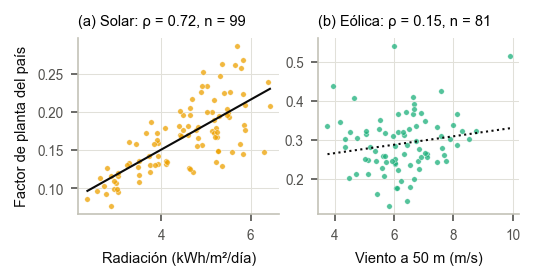

In [3]:
resumen = construir(RAIZ, verbose=False, reusar_operacion=True)   # regenera data/processed/; la simulación horaria (10 min) se reutiliza
# Para rehacerla desde cero: python herramientas/construir_artefactos.py
cal = pd.DataFrame(resumen["calibracion"])
tabla_cal = cal.assign(mejora=lambda x: (1 - x["MAE_cv"] / x["MAE_media_cv"]) * 100)[
    ["tecnologia", "variable", "paises", "rho_spearman", "MAE_media_cv", "MAE_cv", "mejora", "se_usa"]]
display(Markdown("**¿El recurso de NASA predice el factor de planta de cada país?**"))
display(tabla_cal.style.format({"rho_spearman": "{:.2f}", "MAE_media_cv": "{:.4f}", "MAE_cv": "{:.4f}", "mejora": "{:+.1f} %"}).hide(axis="index"))
print("FP solares descartados por ser físicamente incompatibles con la radiación:", resumen["fp_solar_descartados"])
print("FP eólicos descartados por estar fuera del rango creíble:", resumen["fp_eolica_descartados"])

irena = pd.read_csv(RAIZ / "data" / "raw" / "irenastat" / "irenastat_pais_tecnologia.csv")
irena["iso3"] = irena["iso3"].replace({"XKX": "KOS"})
recurso = pa.recurso_por_pais(pd.read_csv(RAIZ / "data" / "raw" / "nasa_power" / "puntos_por_pais.csv"),
                              pd.read_csv(RAIZ / "data" / "raw" / "nasa_power" / "nasa_power_celdas.csv"))
recurso = recurso[recurso["iso3"] != "ATA"]
obs, _ = pa.depurar_solar(pa.fp_observado(irena), recurso)
obs, _ = pa.depurar_eolica(obs, recurso)

fig, ax = plt.subplots(1, 2, figsize=(3.45, 1.75))
for a, tec, var, xlab in ((ax[0], "Solar", "ghi_kwh_m2_dia", "Radiación (kWh/m²/día)"), (ax[1], "Eólica", "viento_max_ms", "Viento a 50 m (m/s)")):
    g = obs[(obs["tecnologia"] == tec) & (obs["cap_media"] >= pa.CAP_MIN_CALIBRAR)].dropna(subset=["fp_obs"]).merge(recurso, on="iso3")
    a.scatter(g[var], g["fp_obs"], s=7, color=TEC_COLOR[tec], alpha=0.75, linewidths=0.25, edgecolors="white")
    i = cal[(cal["tecnologia"] == tec) & (cal["variable"] == var)].iloc[0]
    xs = np.array([g[var].min(), g[var].max()])
    a.plot(xs, i["intercepto"] + i["pendiente"] * xs, color=TINTA, lw=1, ls="-" if i["se_usa"] else ":")
    a.set_xlabel(xlab)
    a.set_title(f"({'a' if tec == 'Solar' else 'b'}) {tec}: ρ = {i['rho_spearman']:.2f}, n = {len(g)}", loc="left")
ax[0].set_ylabel("Factor de planta del país")
fig.tight_layout(pad=0.4)
fig.savefig(FIG / "f4_recurso.png", dpi=240)
plt.show()

**Interpretación.** La **radiación sí predice** el rendimiento solar de un país: la correlación es alta y el error baja cerca de un tercio. El **viento de NASA no predice** el rendimiento eólico: su correlación con el FP es muy débil y casi no reduce el error. Es esperable: el dato tiene una resolución de unos 50 km, mide a 50 m (las turbinas modernas superan los 100 m) y no ve los corredores locales donde se ubican los parques. Por la regla fijada, **no se usa**: en los países sin parques eólicos suficientes la eólica toma el valor mundial y la recomendación se marca como **provisional**.

# 3. Recomendación por país

Se repite el análisis de 14 criterios de la Fase 3 para cada país, con dos criterios locales:

- **Rendimiento:** FP real del país (o estimado por radiación, en la solar), con ± 10 % de incertidumbre.
- **Costo:** el costo nivelado mundial se ajusta en proporción inversa al rendimiento local, limitado a entre la mitad y el doble.

La hidroeléctrica, la geotérmica y la biomasa solo compiten si el país ya tiene esa tecnología instalada, como evidencia de que el recurso existe.

In [4]:
rec = pd.read_csv(PROC / "recomendacion_pais.csv")
fp_tabla = pd.read_csv(PROC / "fp_local.csv")
hoy = rec[rec["escenario"].str.startswith("Hoy")].copy()
display(Markdown("**Renovable recomendada por región (número de países)**"))
tabla_reg = pd.crosstab(hoy["region"], hoy["recomendada"], margins=True, margins_name="Total")
display(tabla_reg)
display(Markdown("**Qué tan clara es la recomendación**"))
display(hoy["certeza"].value_counts().reindex(["Clara", "Moderada", "Reñida"]).to_frame("países").T)
print(f"Coincidencia entre SAW y TOPSIS: {(hoy['recomendada'] == hoy['recomendada_topsis']).mean() * 100:.1f} % de los países")
print(f"Recomendaciones provisionales: {int(hoy['provisional'].sum())} de {len(hoy)}")

# Robustez 1: ¿cambia la recomendación al cambiar la semilla?
paises_rec = sorted(hoy["iso3"])
def top(iso3, semilla):
    return pa.recomendar_pais(d, fp_tabla, iso3, n=4000, semilla=semilla)["% n.º 1"].idxmax()
semillas = [1, 7, 21, 99, 123]
matriz = pd.DataFrame({s: [top(i, s) for i in paises_rec] for s in semillas}, index=paises_rec)
estable = matriz.eq(hoy.set_index("iso3")["recomendada"].reindex(paises_rec), axis=0).all(axis=1)

# Robustez 2: ¿qué aportan los datos locales? Se compara con la recomendación sin rendimiento local
sin_local = fp_tabla.assign(fp_local=np.nan)
base = {i: pa.recomendar_pais(d, sin_local, i, n=4000)["% n.º 1"].idxmax() for i in paises_rec}
cambia = pd.Series(base).reindex(paises_rec).ne(hoy.set_index("iso3")["recomendada"].reindex(paises_rec))
print(f"Misma recomendación con 5 semillas distintas: {estable.mean() * 100:.1f} % de los países")
print(f"Países cuya recomendación cambia gracias a los datos locales: {int(cambia.sum())} de {len(cambia)}")
print("Sin datos locales, recomendación:", pd.Series(base).value_counts().to_dict())
robustez = {"coincidencia_saw_topsis": float((hoy["recomendada"] == hoy["recomendada_topsis"]).mean() * 100), "estable_5_semillas": float(estable.mean() * 100),
            "cambian_por_datos_locales": int(cambia.sum()), "provisionales": int(hoy["provisional"].sum()),
            "certeza": hoy["certeza"].value_counts().to_dict(), "conteo": hoy["recomendada"].value_counts().to_dict()}

**Renovable recomendada por región (número de países)**

recomendada,Eólica,Solar,Total
region,,,
América Latina y el Caribe,3,22,25
América del Norte,0,2,2
Asia meridional,0,5,5
Asia oriental y el Pacífico,2,18,20
Europa y Asia central,14,35,49
"Oriente Medio, Norte de África, Afganistán y Pakistán",4,19,23
África al sur del Sahara,2,40,42
Total,25,141,166


**Qué tan clara es la recomendación**

certeza,Clara,Moderada,Reñida
países,73,52,41


Coincidencia entre SAW y TOPSIS: 87.3 % de los países
Recomendaciones provisionales: 33 de 166


Misma recomendación con 5 semillas distintas: 95.2 % de los países
Países cuya recomendación cambia gracias a los datos locales: 25 de 166
Sin datos locales, recomendación: {'Solar': 166}


Colombia         Solar    41.2 %  |  segunda: Eólica          40.2 %  |  Reñida
Argentina        Eólica   53.5 %  |  segunda: Solar           35.9 %  |  Moderada
Alemania         Solar    42.7 %  |  segunda: Eólica          27.1 %  |  Moderada
India            Solar    63.9 %  |  segunda: Hidroeléctrica  19.4 %  |  Clara
Kenia            Solar    52.5 %  |  segunda: Eólica          24.7 %  |  Clara
Estados Unidos   Solar    52.2 %  |  segunda: Eólica          27.3 %  |  Clara


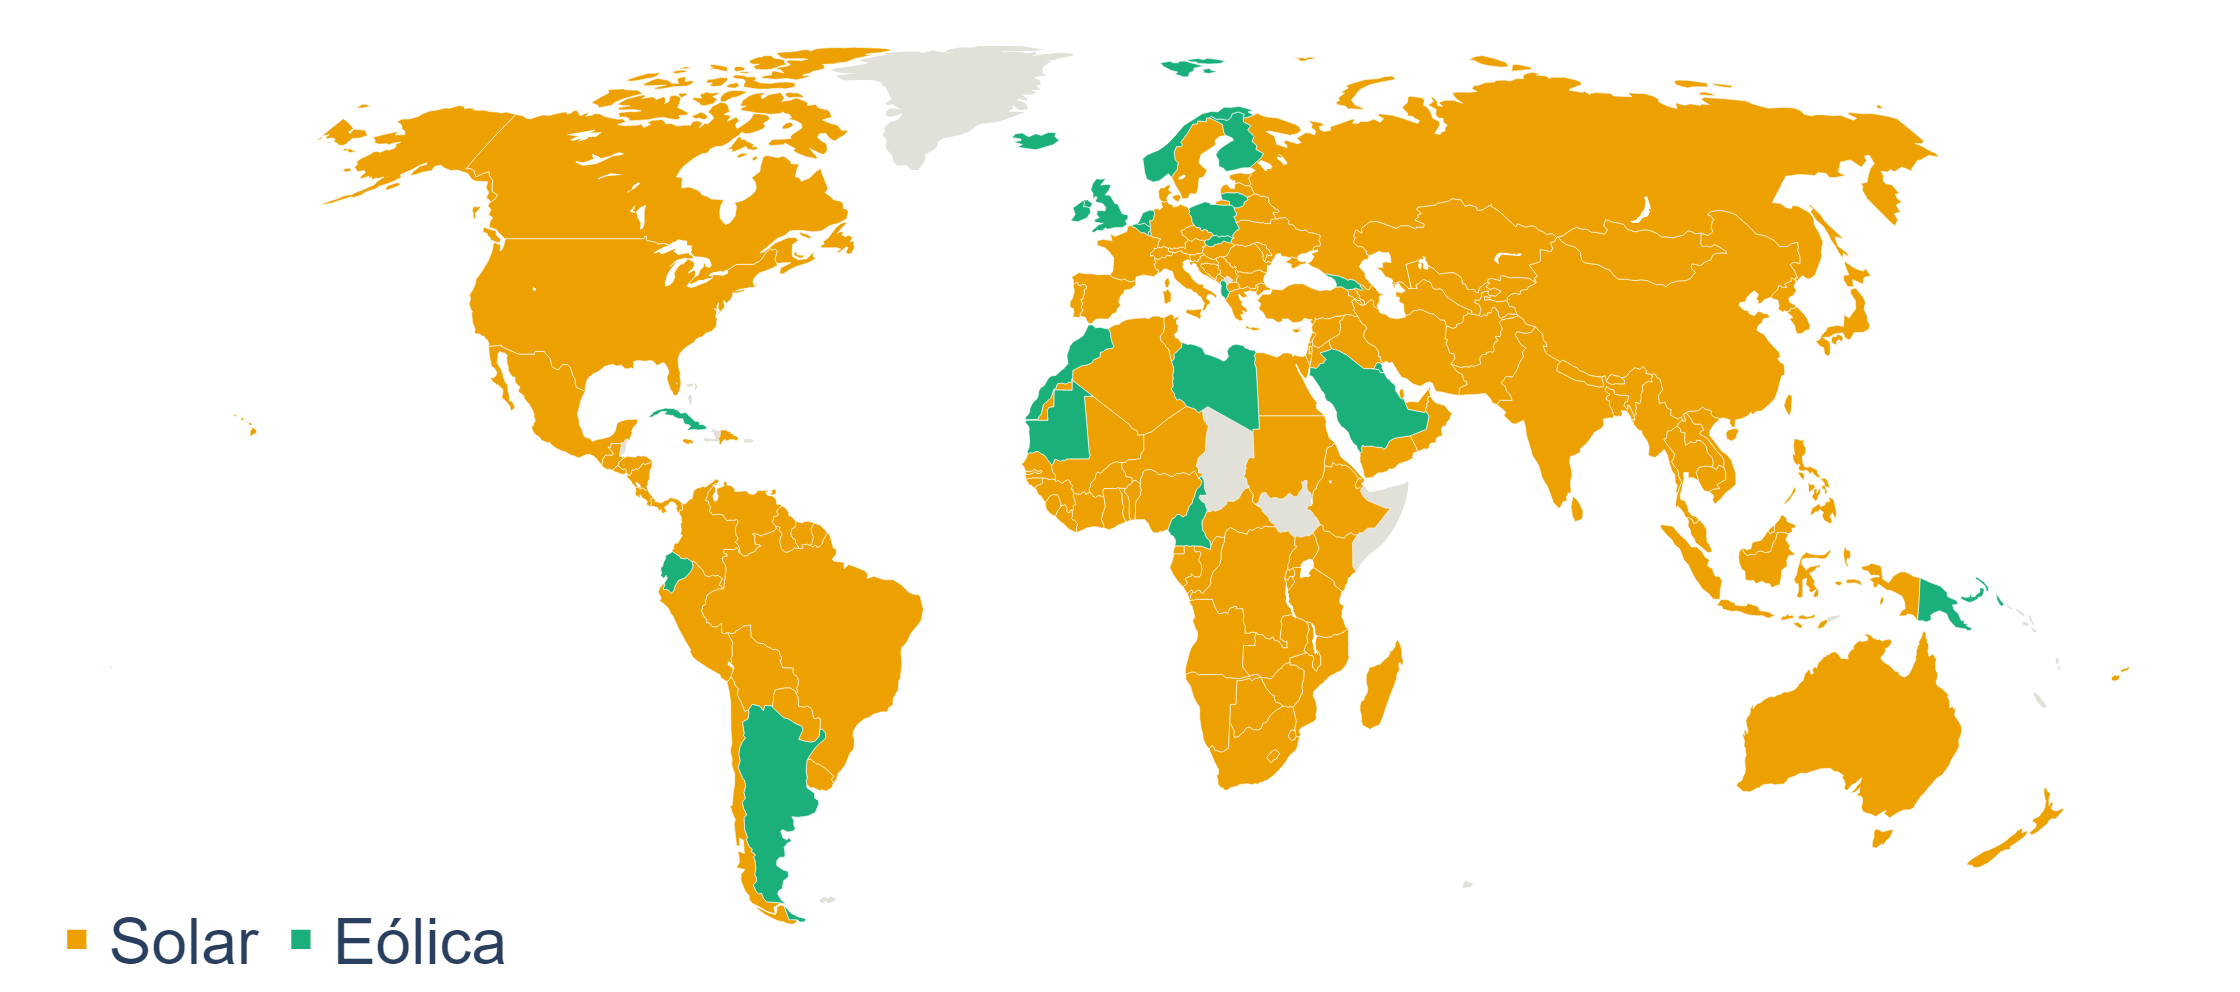

In [5]:
def mapa(tabla, ruta, alto=620):
    f = go.Figure()
    for t in TECS:
        g = tabla[tabla["recomendada"] == t]
        if len(g):
            f.add_choropleth(locations=g["iso3"], z=[1] * len(g), name=t, showlegend=True, showscale=False, colorscale=[[0, TEC_COLOR[t]], [1, TEC_COLOR[t]]],
                             marker=dict(line=dict(color="white", width=0.4)))
    f.update_geos(projection_type="natural earth", showframe=False, showcoastlines=False, showland=True, landcolor="#e1e0d9", showcountries=False, lataxis_range=[-57, 84])
    f.update_layout(width=1400, height=alto, margin=dict(l=0, r=0, t=0, b=0), paper_bgcolor="white",
                    legend=dict(orientation="h", x=0.02, y=0.06, font=dict(size=40, family="Arial"), title_text=""))
    f.write_image(str(ruta), scale=1.6)
    return f

mapa(hoy, FIG / "f4_mapa_paises.png")
for iso in ["COL", "ARG", "DEU", "IND", "KEN", "USA"]:
    f = hoy[hoy["iso3"] == iso].iloc[0]
    print(f"{f['pais']:16} {f['recomendada']:7} {f['pct_primera']:5.1f} %  |  segunda: {f['segunda']:14} {f['pct_segunda']:5.1f} %  |  {f['certeza']}")
from IPython.display import Image
Image(str(FIG / "f4_mapa_paises.png"), width=760)

**Interpretación.** La solar es la opción más frecuente porque es barata y existe en todos los países; la eólica gana donde su rendimiento local es muy alto, como Argentina, Reino Unido o Polonia. La recomendación **no es una orden**: en una parte de los países está reñida, y ahí lo razonable es combinar tecnologías. No incluye la red, la demanda, el financiamiento ni la política de cada país.

# 4. Escenario hipotético: ¿y si la geotérmica con ondas milimétricas fuera un hecho?

La perforación con **ondas milimétricas** busca llegar a roca supercaliente casi en cualquier lugar. Hoy es una hipótesis: Quaise Energy perforó unos 118 m en 2025, informó en julio de 2026 que se acerca a 1 km (sin confirmación independiente) y ningún pozo perforado así ha producido electricidad. Esta sección responde tres preguntas:

1. **¿Qué pasaría?** ¿Cambia la respuesta del proyecto y qué tendría que cumplirse?
2. **¿Cómo se comportaría?** ¿Qué aporta entregar energía a toda hora frente a la solar, la eólica y las baterías?
3. **¿Cuál sería su potencial?** ¿Cuánta energía podría aportar y qué tan rápido?

| Escenario | Costo (USD/MWh) | FP | Países | Crecimiento |
|---|---|---|---|---|
| Prueba de concepto | 45–70 | 0.90 | todos | el actual |
| Madura | 20–35 (Clean Air Task Force, 2022) | 0.90 | todos | como la eólica |

El costo de 20–35 USD/MWh es una **proyección a escala** que supone innovaciones aún no demostradas. La Agencia Internacional de la Energía (AIE, 2024) proyecta unos 50 USD/MWh a 2035. Emisiones, minerales, vida útil y seguridad se dejan como los de la geotérmica actual.

## 4.1 ¿Qué pasaría?

In [6]:
esc = pd.read_csv(PROC / "escenarios_geotermica.csv")
tabla_esc = esc[(esc["metodo"] == "SAW") & esc["con_baterias"]].pivot(index="escenario", columns="tecnologia", values="% n.º 1")[TECS]
orden_esc = ["Hoy (datos de la Fase 3)", "Solo llega a todos los países", "Solo baja el costo (20–35 USD/MWh)", "Prueba de concepto", "Madura (meta de la industria)"]
tabla_esc = tabla_esc.loc[orden_esc]
display(Markdown("**% de escenarios en primer lugar (20 000 escenarios, SAW)**"))
display(tabla_esc.style.format("{:.1f}"))
for metodo, bat, nombre in (("TOPSIS", True, "TOPSIS"), ("SAW", False, "SAW sin baterías")):
    m = esc[(esc["metodo"] == metodo) & (esc["con_baterias"] == bat) & esc["escenario"].str.startswith("Madura")].set_index("tecnologia")["% n.º 1"]
    print(f"Escenario maduro con {nombre}: geotérmica {m['Geotérmica']:.1f} % | solar {m['Solar']:.1f} % | eólica {m['Eólica']:.1f} %")
madura_rec = rec[rec["escenario"].str.startswith("Madura")]["recomendada"].value_counts().to_dict()
print("Recomendación por país en el escenario maduro:", madura_rec)

geo_res = json.loads((PROC / "geo_resumen.json").read_text(encoding="utf-8"))
cond = pd.read_csv(PROC / "geo_condiciones.csv")
riv = pd.read_csv(PROC / "geo_rivales.csv")
g50 = cond[(cond["costo_medio"] == 50) & (cond["fp"] == 0.90) & cond["crece_como_eolica"]].iloc[0]
r40 = riv[riv["caida_rivales"] == 40].set_index("metodo")
caida = tabla_esc.loc[orden_esc[0]] - tabla_esc.loc[orden_esc[-1]]          # puntos que pierde cada tecnología de «Hoy» a «Madura»
print(f"\nCosto de empate con la solar: {geo_res['quiebre_con_crecimiento']:.1f} USD/MWh si crece como la eólica; {geo_res['quiebre_sin_crecimiento']:.1f} si no")
print(f"Con la meta de la AIE (50 USD/MWh): geotérmica {g50['geotermica']:.1f} % | mejor rival {g50['mejor_rival']:.1f} %")
print(f"Madura, si la solar y la eólica caen otro 40 %: SAW {r40.loc['SAW', 'Geotérmica']:.1f} contra {r40.loc['SAW', 'Solar']:.1f} | TOPSIS {r40.loc['TOPSIS', 'Geotérmica']:.1f} contra {r40.loc['TOPSIS', 'Solar']:.1f}")
display(Markdown(f"""**Interpretación.** Una sola mejora no basta. La geotérmica solo queda primera si llega a todos los países, crece como la eólica y cuesta menos de unos **{geo_res['quiebre_con_crecimiento']:.0f} USD/MWh**. Con la meta de la AIE (50 USD/MWh) **no alcanzaría** el primer lugar. Y si la solar y la eólica se abaratan otro 40 %, como proyecta IRENA para la solar con baterías a 2035, la ventaja se reduce a un **empate técnico** con SAW ({r40.loc['SAW', 'Geotérmica']:.1f} % contra {r40.loc['SAW', 'Solar']:.1f} %).

En el escenario maduro, los **{-caida['Geotérmica']:.0f} puntos** que gana la geotérmica salen sobre todo de la **eólica** ({caida['Eólica']:.0f} puntos), seguida de la solar ({caida['Solar']:.0f}), la hidroeléctrica ({caida['Hidroeléctrica']:.0f}) y la biomasa ({caida['Biomasa']:.0f})."""))

**% de escenarios en primer lugar (20 000 escenarios, SAW)**

tecnologia,Solar,Eólica,Hidroeléctrica,Geotérmica,Biomasa
escenario,,,,,
Hoy (datos de la Fase 3),45.7,35.9,12.4,3.7,2.3
Solo llega a todos los países,43.7,31.7,11.4,11.4,1.8
Solo baja el costo (20–35 USD/MWh),43.6,28.1,11.1,15.2,1.9
Prueba de concepto,42.0,28.3,10.0,18.2,1.5
Madura (meta de la industria),30.8,18.1,7.1,42.9,1.2


Escenario maduro con TOPSIS: geotérmica 35.0 % | solar 27.2 % | eólica 21.1 %
Escenario maduro con SAW sin baterías: geotérmica 31.6 % | solar 44.8 % | eólica 18.0 %
Recomendación por país en el escenario maduro: {'Geotérmica': 160, 'Solar': 6}

Costo de empate con la solar: 39.0 USD/MWh si crece como la eólica; 27.3 si no
Con la meta de la AIE (50 USD/MWh): geotérmica 27.3 % | mejor rival 37.6 %
Madura, si la solar y la eólica caen otro 40 %: SAW 35.8 contra 35.2 | TOPSIS 31.9 contra 29.2


**Interpretación.** Una sola mejora no basta. La geotérmica solo queda primera si llega a todos los países, crece como la eólica y cuesta menos de unos **39 USD/MWh**. Con la meta de la AIE (50 USD/MWh) **no alcanzaría** el primer lugar. Y si la solar y la eólica se abaratan otro 40 %, como proyecta IRENA para la solar con baterías a 2035, la ventaja se reduce a un **empate técnico** con SAW (35.8 % contra 35.2 %).

En el escenario maduro, los **39 puntos** que gana la geotérmica salen sobre todo de la **eólica** (18 puntos), seguida de la solar (15), la hidroeléctrica (5) y la biomasa (1).

## 4.2 ¿Cómo se comportaría?

El ranking anual no ve lo más valioso de la geotérmica: **entrega energía a toda hora**. Para medirlo se simula un consumo constante de 100 MW en seis países durante 2022–2024 (26 304 horas), con 95 % de confiabilidad, el mismo nivel de energía firme que usa IRENA (2026):

- **Generación:** forma hora a hora de NASA POWER, reescalada al FP anual del país. Si el país tiene menos de 50 MW o su dato no es creíble, se usa el FP mundial de plantas nuevas.
- **Baterías:** 140 USD/kWh y 4 h (IRENA, 2026), 85 % de eficiencia, 15 años, tasa del 7 % y 2 % anual de operación.
- **Búsqueda:** la combinación de solar, eólica y baterías de menor costo, con despacho hora a hora. Se paga también la energía que se desperdicia. En ventanas de 45 días, la búsqueda coincidió con un programa lineal exacto (diferencia máxima de 0.03 %).
- **A 2035:** la solar y las baterías bajan 40 % (IRENA, 2026), la eólica se mantiene y la mezcla se vuelve a optimizar.

In [7]:
op = pd.read_csv(PROC / "geo_operacion.csv")
vista = op.pivot(index="pais", columns="mezcla", values="costo_firme_2025").join(
    op[op["mezcla"] == "Solar + eólica + baterías"].set_index("pais")[["costo_firme_2035", "solar_mw", "eolica_mw", "bateria_mwh", "vertida_pct", "terreno_ha", "minerales_t"]])
vista = vista.sort_values("Solar + eólica + baterías")
display(Markdown("**Abastecer 100 MW constantes con 95 % de confiabilidad (costos en USD/MWh)**"))
display(vista.style.format("{:.0f}"))
f0 = op.iloc[0]
print(f"La geotérmica necesitaría {f0['geo_mw']:.0f} MW, {f0['geo_terreno_ha']:.0f} ha y {f0['geo_minerales_t']:.0f} t de minerales críticos, sin baterías")
mix = op[op["mezcla"] == "Solar + eólica + baterías"]
print(f"Países donde 50 USD/MWh (AIE) es más barato que la mezcla: hoy {int((mix['costo_firme_2025'] > 50).sum())} de 6; en 2035 {int((mix['costo_firme_2035'] > 50).sum())} de 6")
print(f"Países donde 89 USD/MWh (geotérmica de hoy) es más barato: hoy {int((mix['costo_firme_2025'] > 89).sum())} de 6")
solo = op[op["mezcla"] == "Solar + baterías"].set_index("pais")["costo_firme_2025"]
print(f"Validación externa, solar + baterías: {solo.round(0).astype(int).to_dict()} USD/MWh; IRENA reporta 54–82 en sitios de alta calidad")
display(Markdown(f"""**Interpretación.** Como fuente de energía **firme**, la geotérmica compite mucho antes que en el ranking general. Hoy, abastecer un consumo constante con solar, eólica y baterías cuesta entre **{mix['costo_firme_2025'].min():.0f} y {mix['costo_firme_2025'].max():.0f} USD/MWh** en estos países. Su ventaja es mayor donde hay poco sol en invierno, como Alemania, y menor donde el sol y el viento se complementan. A cambio usa mucho menos terreno, pero **más minerales críticos**. Es un complemento de la solar y la eólica, no su reemplazo."""))

**Abastecer 100 MW constantes con 95 % de confiabilidad (costos en USD/MWh)**

,Solar + baterías,Solar + eólica + baterías,costo_firme_2035,solar_mw,eolica_mw,bateria_mwh,vertida_pct,terreno_ha,minerales_t
pais,,,,,,,,,
Kenia,69,52,40,134,278,299,26,637,4222
Colombia,76,52,43,90,320,207,28,423,4205
Estados Unidos,99,54,43,190,258,350,25,772,4490
Chile,77,66,46,254,228,847,25,1266,5429
India,84,82,50,604,90,1204,16,1845,6986
Alemania,332,129,100,577,481,1194,43,1207,10764


La geotérmica necesitaría 111 MW, 39 ha y 21443 t de minerales críticos, sin baterías
Países donde 50 USD/MWh (AIE) es más barato que la mezcla: hoy 6 de 6; en 2035 2 de 6
Países donde 89 USD/MWh (geotérmica de hoy) es más barato: hoy 1 de 6
Validación externa, solar + baterías: {'Colombia': 76, 'Alemania': 332, 'Kenia': 69, 'Chile': 77, 'Estados Unidos': 99, 'India': 84} USD/MWh; IRENA reporta 54–82 en sitios de alta calidad


**Interpretación.** Como fuente de energía **firme**, la geotérmica compite mucho antes que en el ranking general. Hoy, abastecer un consumo constante con solar, eólica y baterías cuesta entre **52 y 129 USD/MWh** en estos países. Su ventaja es mayor donde hay poco sol en invierno, como Alemania, y menor donde el sol y el viento se complementan. A cambio usa mucho menos terreno, pero **más minerales críticos**. Es un complemento de la solar y la eólica, no su reemplazo.

## 4.3 ¿Cuál sería su potencial?

La AIE estima casi **600 TW** de potencial técnico a menos de 8 km, de modo que el calor no es el límite. El límite es la velocidad de construcción. Se proyecta qué ocurriría si, tras seguir su tendencia actual hasta despegar, la geotérmica repitiera la **expansión real** de la eólica o de la solar desde que tenían su tamaño actual (unos 16 GW), con un FP de 0.85. Es una analogía, no un pronóstico.

**Geotérmica en 2050 según cómo crezca**

,gw,twh,pct_demanda_2025,gt_co2_gas,gt_co2_carbon
trayectoria,,,,,
Sigue como hoy,31,233,0.7 %,0.1,0.2
Como la eólica desde 2035,506,3767,11.9 %,1.7,2.9
Como la eólica desde 2030,776,5777,18.2 %,2.6,4.5
Como la solar desde 2035,1927,14349,45.2 %,6.5,11.2


**Interpretación.** Si despega en 2030 y crece como la eólica, tendría unos **776 GW** en 2050, del mismo orden que los 800 GW que proyecta la AIE. Generaría **5777 TWh al año**, el equivalente al **18 %** de la electricidad mundial de 2025, y evitaría de 2.6 a 4.5 Gt de CO₂ al año si reemplaza gas o carbón. Si no despega, seguiría siendo marginal (0.7 %). El momento pesa mucho: empezar en 2035 en lugar de 2030 deja la capacidad de 2050 en el 65 %.

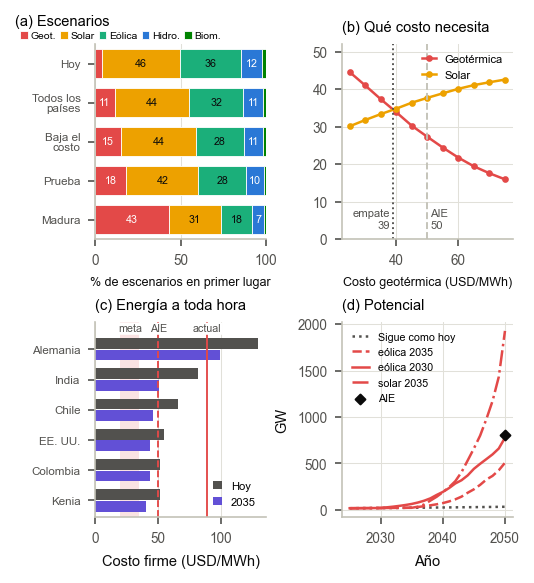

In [8]:
pot = pd.read_csv(PROC / "geo_potencial.csv")
fin = pot[pot["anio"] == 2050].set_index("trayectoria")[["gw", "twh", "pct_demanda_2025", "gt_co2_gas", "gt_co2_carbon"]]
display(Markdown("**Geotérmica en 2050 según cómo crezca**"))
display(fin.style.format({"gw": "{:.0f}", "twh": "{:.0f}", "pct_demanda_2025": "{:.1f} %", "gt_co2_gas": "{:.1f}", "gt_co2_carbon": "{:.1f}"}))
e30, e35 = fin.loc["Como la eólica desde 2030"], fin.loc["Como la eólica desde 2035"]
display(Markdown(f"""**Interpretación.** Si despega en 2030 y crece como la eólica, tendría unos **{e30['gw']:.0f} GW** en 2050, del mismo orden que los 800 GW que proyecta la AIE. Generaría **{e30['twh']:.0f} TWh al año**, el equivalente al **{e30['pct_demanda_2025']:.0f} %** de la electricidad mundial de 2025, y evitaría de {e30['gt_co2_gas']:.1f} a {e30['gt_co2_carbon']:.1f} Gt de CO₂ al año si reemplaza gas o carbón. Si no despega, seguiría siendo marginal ({fin.loc['Sigue como hoy', 'pct_demanda_2025']:.1f} %). El momento pesa mucho: empezar en 2035 en lugar de 2030 deja la capacidad de 2050 en el {e35['gw'] / e30['gw'] * 100:.0f} %."""))

fig, axs = plt.subplots(2, 2, figsize=(3.45, 3.75))
ax = axs.ravel()
# (a) Las cinco tecnologías suman 100 % en cada escenario; la geotérmica va primero para que su avance se lea desde el eje
etiquetas = ["Hoy", "Todos los\npaíses", "Baja el\ncosto", "Prueba", "Madura"]
apilado = {"Geotérmica": "Geot.", "Solar": "Solar", "Eólica": "Eólica", "Hidroeléctrica": "Hidro.", "Biomasa": "Biom."}
y = np.arange(len(etiquetas))[::-1]
izq = np.zeros(len(etiquetas))
for t, corto in apilado.items():
    v = tabla_esc[t].values
    ax[0].barh(y, v, 0.72, left=izq, color=TEC_COLOR[t], edgecolor="white", linewidth=0.4, label=corto)
    for yi, l, vi in zip(y, izq, v):
        if vi >= 7:                                   # los segmentos más angostos no tienen espacio para el número
            ax[0].text(l + vi / 2, yi, f"{vi:.0f}", ha="center", va="center", fontsize=5.2, color=TINTA if t in ("Solar", "Eólica") else "white")
    izq += v
ax[0].set_yticks(y, etiquetas, fontsize=5.6, linespacing=0.95); ax[0].grid(axis="y", visible=False); ax[0].set_xlim(0, 100); ax[0].set_ylim(-0.5, len(etiquetas) - 0.5)
ax[0].set_xticks([0, 50, 100], ["0", "50", "100"]); ax[0].set_xlabel("% de escenarios en primer lugar", fontsize=6)
ax[0].legend(ncol=5, loc="lower left", bbox_to_anchor=(-0.47, 0.99), handlelength=0.7, columnspacing=0.45, handletextpad=0.25, fontsize=5.0, borderaxespad=0.1)
ax[0].set_title("(a) Escenarios", loc="left", x=-0.47, pad=9)

g = cond[(cond["fp"] == 0.90) & cond["crece_como_eolica"]].sort_values("costo_medio")
ax[1].plot(g["costo_medio"], g["geotermica"], color=TEC_COLOR["Geotérmica"], marker="o", ms=2.2, label="Geotérmica")
ax[1].plot(g["costo_medio"], g["mejor_rival"], color=TEC_COLOR["Solar"], marker="o", ms=2.2, label="Solar")
q = geo_res["quiebre_con_crecimiento"]
ax[1].axvline(q, color=TINTA2, ls=":", lw=0.9); ax[1].text(q - 1, 3, f"empate\n{q:.0f}", fontsize=5.4, color=TINTA2, ha="right")
ax[1].axvline(50, color=GRIS, ls="--", lw=0.9); ax[1].text(51, 3, "AIE\n50", fontsize=5.4, color=TINTA2)
ax[1].set_xlabel("Costo geotérmica (USD/MWh)", fontsize=6); ax[1].set_ylim(0, 52); ax[1].legend(loc="upper right", handlelength=1.2, fontsize=5.4)
ax[1].set_title("(b) Qué costo necesita", loc="left")

m = op[op["mezcla"] == "Solar + eólica + baterías"].sort_values("costo_firme_2025")
y = np.arange(len(m))
ax[2].axvspan(20, 35, color=TEC_COLOR["Geotérmica"], alpha=0.15, lw=0)
ax[2].barh(y + 0.19, m["costo_firme_2025"], 0.36, color=TINTA2, label="Hoy")
ax[2].barh(y - 0.19, m["costo_firme_2035"], 0.36, color="#6250d6", label="2035")
ax[2].axvline(50, color=TEC_COLOR["Geotérmica"], ls="--", lw=0.9); ax[2].axvline(89, color=TEC_COLOR["Geotérmica"], lw=0.9)
for xv, txt in ((27.5, "meta"), (50, "AIE"), (89, "actual")):
    ax[2].text(xv, len(m) - 0.42, txt, fontsize=5.2, color=TINTA2, ha="center", bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none"))
ax[2].set_yticks(y, [p.replace("Estados Unidos", "EE. UU.") for p in m["pais"]], fontsize=5.6); ax[2].grid(axis="y", visible=False); ax[2].set_ylim(-0.55, len(m) - 0.1)
ax[2].set_xlabel("Costo firme (USD/MWh)"); ax[2].legend(loc="lower right", handlelength=0.8, fontsize=5.4)
ax[2].set_title("(c) Energía a toda hora", loc="left")

for nombre, ls, col in (("Sigue como hoy", ":", TINTA2), ("Como la eólica desde 2035", "--", TEC_COLOR["Geotérmica"]), ("Como la eólica desde 2030", "-", TEC_COLOR["Geotérmica"]), ("Como la solar desde 2035", "-.", TEC_COLOR["Geotérmica"])):
    s = pot[pot["trayectoria"] == nombre]
    ax[3].plot(s["anio"], s["gw"], ls=ls, color=col, label=nombre.replace("Como la ", "").replace(" desde ", " "))
ax[3].scatter([2050], [800], marker="D", s=11, color=TINTA, zorder=5, label="AIE")
ax[3].set_xlabel("Año"); ax[3].set_ylabel("GW"); ax[3].legend(loc="upper left", handlelength=1.6, fontsize=5.2)
ax[3].set_title("(d) Potencial", loc="left")
fig.tight_layout(pad=0.3, w_pad=0.6, h_pad=0.7)
fig.savefig(FIG / "f4_geotermica.png", dpi=300)
plt.show()

## 4.4 ¿Y si cada renovable da su gran salto? (exploratorio)

La geotérmica no es la única que puede mejorar. Este ejercicio traduce un **gran salto** de la solar, la eólica, la hidroeléctrica y la biomasa en cambios de sus criterios
y repite el mismo Monte Carlo de 20 000 escenarios (`src/renovables/saltos.py`; vista 9 del tablero). Se comparan tres situaciones: hoy, si solo una tecnología da el salto
y si todas lo dan a la vez junto con la geotérmica madura. Después se fija un pilar cinco veces más importante que cada uno de los demás.

Ninguna tecnología puede superar su techo físico: un panel de 2 × 2 cm recibe como máximo 0.4 W de sol a mediodía, aunque fuera perfecto. Por eso el salto está en el costo, la escala, la duración y el reciclaje.

**Supuestos del gran salto de cada tecnología** (ilustrativos)

Gran salto
Tecnología     Palanca                                     
Solar          Eficiencia del panel (%)                  40
               Cambio del costo (%)                     -60
               Vida útil (años)                          40
               Reciclaje (% de la masa)                  95
Eólica         Factor de planta                         0.5
               Cambio del costo (%)                     -50
               Vida útil (años)                          35
               Reciclaje (% de la masa)                  97
               Crece como la solar (26 % al año)         no
Hidroeléctrica Energía extra por modernizar (%)          10
               Cambio del costo (%)                     -25
               Vida útil (años)                          80
               Crece como la solar (26 % al año)         no
Biomasa        Combustible de residuos (%)              100
               Mejora de la conversión (%)               30
               Captura de carbono (BECCS)                sí
               Cambio del costo (%)                       0
               Crece como la solar (26 % al año)         no

% de escenarios en primer lugar (gran salto; «todas» incluye la geotérmica madura)
                 Hoy  Si solo ella da el salto  Si todas lo dan a la vez
Solar           45.7                      80.3                      48.5
Eólica          35.9                      69.2                      21.0
Hidroeléctrica  12.4                      21.5                       8.0
Geotérmica       3.7                      42.9                      18.2
Biomasa          2.3                      18.7                       4.3

Ganadora con cada prioridad (todas dan el salto):
                                 ganadora      %
Ninguna (pesos al azar)             Solar   48.5
Confiabilidad                  Geotérmica   89.8
Economía y acceso              Geotérmica   79.8
Ambiente y seguridad                Solar   50.0
Materiales y circularidad  Hidroeléctrica   99.4
Trayectoria y futuro                Solar  100.0


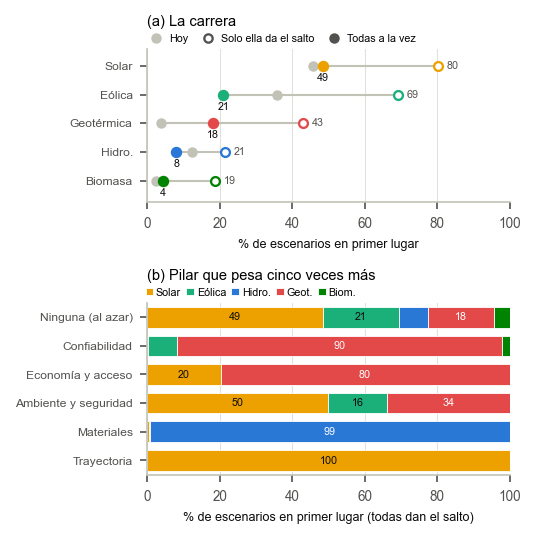

**Interpretación.** Si solo una da el salto, puede ganar: la solar llegaría al 80 % de los escenarios y la eólica al 69 %.
Si todas lo dan a la vez, junto con la geotérmica madura, gana la solar (49 %), pero ninguna llega tan lejos como si mejorara sola:
el modelo compara a las cinco entre sí. Con un pilar cinco veces más importante, la ganadora cambia (confiabilidad: geotérmica (90 %); economía y acceso: geotérmica (80 %); ambiente y seguridad: solar (50 %); materiales y circularidad: hidroeléctrica (99 %); trayectoria y futuro: solar (100 %)). No hay un ganador único.
Los niveles son supuestos ilustrativos: es un ejercicio exploratorio, no un pronóstico.

In [9]:
palancas = [{"Tecnología": t, "Palanca": p_["etiqueta"], "Gran salto": ("sí" if v else "no") if p_.get("tipo") == "toggle" else f"{v:g}"}
            for t in sa.PALANCAS for p_, v in ((p_, p_["niveles"][2]) for p_ in sa.PALANCAS[t])]
display(Markdown("**Supuestos del gran salto de cada tecnología** (ilustrativos)"))
display(pd.DataFrame(palancas).set_index(["Tecnología", "Palanca"]))
crit = pd.read_csv(PROC / "criterios.csv", index_col=0).reindex(TECS)
geo_madura = mc.aplicar_escenario_geo(crit, **mc.ESCENARIOS_GEO["Madura (meta de la industria)"])
gran = {t: sa.valores_nivel(t, "Gran salto") for t in sa.PALANCAS}


def primer_lugar(d, prioridad=None):
    pesos = mc.pesos_desde_pilares(prioridad) if prioridad else None
    return mc.resumen_puestos(mc.simular(d, 20000, np.random.default_rng(42), pesos=pesos))["% n.º 1"]


hoy = primer_lugar(crit)
sola = pd.Series({t: primer_lugar(sa.aplicar_salto(crit, t, gran[t]))[t] for t in sa.PALANCAS} | {"Geotérmica": primer_lugar(geo_madura)["Geotérmica"]})
todas_d = sa.aplicar_saltos(geo_madura, gran)
todas = primer_lugar(todas_d)
carrera = pd.DataFrame({"Hoy": hoy, "Si solo ella da el salto": sola, "Si todas lo dan a la vez": todas}).loc[TECS]
prioridades = {"Ninguna (pesos al azar)": None} | {p: {q: 5 if q == p else 1 for q in mc.PILARES} for p in mc.PILARES}
por_prioridad = pd.DataFrame({nombre: primer_lugar(todas_d, pr) for nombre, pr in prioridades.items()}).T[TECS]
print("% de escenarios en primer lugar (gran salto; «todas» incluye la geotérmica madura)")
print(carrera.round(1).to_string())
print("\nGanadora con cada prioridad (todas dan el salto):")
print(pd.DataFrame({"ganadora": por_prioridad.idxmax(axis=1), "%": por_prioridad.max(axis=1).round(1)}).to_string())

fig = plt.figure(figsize=(3.45, 3.55))
gs = fig.add_gridspec(2, 1, height_ratios=[1, 1.12], hspace=0.62)
ax0, ax1 = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])
orden = carrera["Si todas lo dan a la vez"].sort_values().index
y = np.arange(len(orden))
for yi, t in zip(y, orden):
    v = carrera.loc[t]
    ax0.plot([v.min(), v.max()], [yi, yi], color=GRIS, lw=1.0, zorder=1)
    ax0.scatter(v["Hoy"], yi, s=16, color=GRIS, zorder=2)
    ax0.scatter(v["Si solo ella da el salto"], yi, s=18, facecolor="white", edgecolor=TEC_COLOR[t], linewidth=1.1, zorder=3)
    ax0.scatter(v["Si todas lo dan a la vez"], yi, s=20, color=TEC_COLOR[t], zorder=4)
    ax0.text(v["Si solo ella da el salto"] + 2.4, yi, f"{v['Si solo ella da el salto']:.0f}", fontsize=5.2, color=TINTA2, ha="left", va="center")
    ax0.text(v["Si todas lo dan a la vez"], yi - 0.52, f"{v['Si todas lo dan a la vez']:.0f}", fontsize=5.2, color=TINTA, ha="center")
ax0.set_yticks(y, [t.replace("Hidroeléctrica", "Hidro.") for t in orden], fontsize=5.8); ax0.set_ylim(-0.75, len(orden) - 0.4)
ax0.set_xlim(0, 100); ax0.grid(axis="y", visible=False); ax0.set_xlabel("% de escenarios en primer lugar", fontsize=6)
for etiqueta, kw in (("Hoy", dict(color=GRIS)), ("Solo ella da el salto", dict(facecolor="white", edgecolor=TINTA2, linewidth=1.1)),
                     ("Todas a la vez", dict(color=TINTA2))):
    ax0.scatter([], [], s=16, label=etiqueta, **kw)
ax0.legend(ncol=3, loc="lower left", bbox_to_anchor=(-0.02, 1.0), handletextpad=0.2, columnspacing=0.8, fontsize=5.2, borderaxespad=0.1)
ax0.set_title("(a) La carrera", loc="left", pad=11)

filas = list(por_prioridad.index)[::-1]
corto = {"Ninguna (pesos al azar)": "Ninguna (al azar)", "Materiales y circularidad": "Materiales", "Trayectoria y futuro": "Trayectoria"}
izq = np.zeros(len(filas))
abrev = {"Geotérmica": "Geot.", "Solar": "Solar", "Eólica": "Eólica", "Hidroeléctrica": "Hidro.", "Biomasa": "Biom."}
for t in TECS:
    v = por_prioridad.loc[filas, t].values
    ax1.barh(np.arange(len(filas)), v, 0.72, left=izq, color=TEC_COLOR[t], edgecolor="white", linewidth=0.4, label=abrev[t])
    for yi, l, vi in zip(np.arange(len(filas)), izq, v):
        if vi >= 12:
            ax1.text(l + vi / 2, yi, f"{vi:.0f}", ha="center", va="center", fontsize=5.2, color=TINTA if t in ("Solar", "Eólica") else "white")
    izq += v
ax1.set_yticks(np.arange(len(filas)), [corto.get(f, f) for f in filas], fontsize=5.8); ax1.set_xlim(0, 100); ax1.set_ylim(-0.5, len(filas) - 0.5)
ax1.grid(axis="y", visible=False); ax1.set_xlabel("% de escenarios en primer lugar (todas dan el salto)", fontsize=6)
ax1.legend(ncol=5, loc="lower left", bbox_to_anchor=(-0.02, 1.0), handlelength=0.7, columnspacing=0.5, handletextpad=0.25, fontsize=5.2, borderaxespad=0.1)
ax1.set_title("(b) Pilar que pesa cinco veces más", loc="left", pad=11)
fig.subplots_adjust(left=0.27, right=0.97, top=0.9, bottom=0.1)
fig.savefig(FIG / "f4_saltos.png", dpi=300)
plt.show()
ganadoras = "; ".join(f"{p_.lower()}: {por_prioridad.loc[p_].idxmax().lower()} ({por_prioridad.loc[p_].max():.0f} %)" for p_ in mc.PILARES)
display(Markdown(f"""**Interpretación.** Si solo una da el salto, puede ganar: la solar llegaría al {sola['Solar']:.0f} % de los escenarios y la eólica al {sola['Eólica']:.0f} %.
Si todas lo dan a la vez, junto con la geotérmica madura, gana la {todas.idxmax().lower()} ({todas.max():.0f} %), pero ninguna llega tan lejos como si mejorara sola:
el modelo compara a las cinco entre sí. Con un pilar cinco veces más importante, la ganadora cambia ({ganadoras}). No hay un ganador único.
Los niveles son supuestos ilustrativos: es un ejercicio exploratorio, no un pronóstico."""))

# 5. Artefactos y cumplimiento

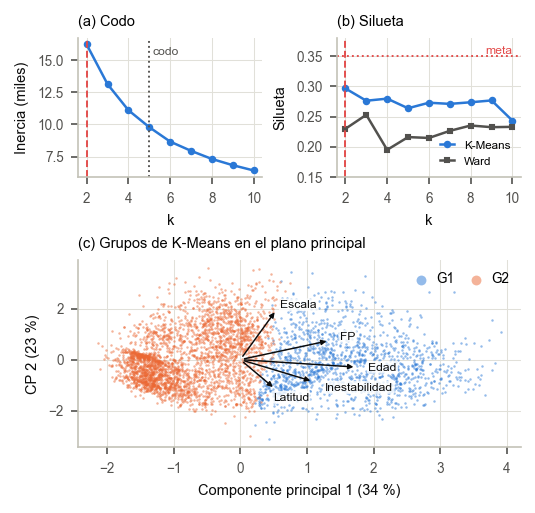

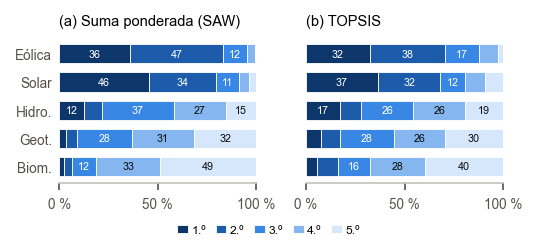

In [10]:
# Figuras de segmentación y multicriterio con el formato final del informe (mismos resultados de la Fase 3)
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

COLOR_G = {"G1": "#2a78d6", "G2": "#eb6834"}                 # los mismos colores del tablero
dc = dm.dropna(subset=["edad_planta", "cv_generacion"]).copy()
dc["log_cv"] = np.log(dc["cv_generacion"] + 0.01)
Zc = StandardScaler().fit_transform(dc[list(VARS_CLUSTER)])
ks = list(range(2, 11))
km_k = [KMeans(n_clusters=k, n_init=50, random_state=SEMILLA).fit(Zc) for k in ks]
inercia = [m.inertia_ / 1000 for m in km_k]
sil_km = [silhouette_score(Zc, m.labels_) for m in km_k]
sil_w = [silhouette_score(Zc, AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(Zc)) for k in ks]
assert abs(sil_km[0] - 0.297) < 0.001

pl = pd.read_csv(PROC / "plantas.csv").dropna(subset=["grupo_kmeans"])
fig = plt.figure(figsize=(3.45, 3.3))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.35])
a, b, c = fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]), fig.add_subplot(gs[1, :])
a.plot(ks, inercia, color="#2a78d6", marker="o", ms=2.6); a.axvline(2, color="#e34948", ls="--", lw=0.9); a.axvline(5, color=TINTA2, ls=":", lw=0.9)
a.text(5.15, max(inercia) * 0.95, "codo", fontsize=5.8, color=TINTA2)
a.set_xticks(range(2, 11, 2)); a.set_xlabel("k"); a.set_ylabel("Inercia (miles)"); a.set_title("(a) Codo", loc="left")
b.plot(ks, sil_km, color="#2a78d6", marker="o", ms=2.6, label="K-Means"); b.plot(ks, sil_w, color=TINTA2, marker="s", ms=2.2, label="Ward")
b.axhline(0.35, color="#e34948", ls=":", lw=0.9); b.axvline(2, color="#e34948", ls="--", lw=0.9); b.text(10, 0.355, "meta", fontsize=5.8, color="#e34948", ha="right")
b.set_xticks(range(2, 11, 2)); b.set_ylim(0.15, 0.38); b.set_xlabel("k"); b.set_ylabel("Silueta"); b.legend(loc="lower right", handlelength=1.2, fontsize=5.6); b.set_title("(b) Silueta", loc="left")
for g_, col in COLOR_G.items():
    v = pl[pl["grupo_kmeans"] == g_]
    c.scatter(v["pc1"], v["pc2"], s=1.4, color=col, alpha=0.5, linewidths=0, label=g_, rasterized=True)
cargas = resumen["clustering"]["cargas_pca"]
cortos = {"Escala (log₁₀ MW)": ("Escala", 0.05, 0.16), "Distancia al ecuador (°)": ("Latitud", -0.05, -0.30), "Edad (años)": ("Edad", 0.16, 0.0),
          "Factor de planta": ("FP", 0.14, 0.16), "Inestabilidad (log CV)": ("Inestabilidad", 0.16, -0.22)}
for lab, (corto, dx, dy) in cortos.items():
    x_, y_ = cargas[lab][0] * 2.6, cargas[lab][1] * 2.6
    c.annotate("", xy=(x_, y_), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=TINTA, lw=0.7, mutation_scale=5))
    c.text(x_ + dx, y_ + dy, corto, fontsize=5.8, color=TINTA, ha="left" if x_ >= 0 else "right", va="center",
           bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=0.8))
var = resumen["clustering"]["pca_varianza"]
c.set_xlabel(f"Componente principal 1 ({var[0] * 100:.0f} %)"); c.set_ylabel(f"CP 2 ({var[1] * 100:.0f} %)")
c.legend(loc="upper right", ncol=2, markerscale=4, handletextpad=0.1, columnspacing=0.6); c.set_title("(c) Grupos de K-Means en el plano principal", loc="left")
fig.tight_layout(pad=0.4, h_pad=0.6, w_pad=0.8)
fig.savefig(FIG / "f4_clustering.png", dpi=260)
plt.show()

rng = np.random.default_rng(SEMILLA)
P_saw, P_top = mc.simular(d, 20000, rng, "SAW"), mc.simular(d, 20000, rng, "TOPSIS")
assert abs((P_saw[:, 0] == 1).mean() * 100 - 45.72) < 0.01 and abs((P_top[:, 0] == 1).mean() * 100 - 36.57) < 0.01
orden_t = ["Eólica", "Solar", "Hidroeléctrica", "Geotérmica", "Biomasa"]
nombre_t = {"Hidroeléctrica": "Hidro.", "Geotérmica": "Geot.", "Biomasa": "Biom."}
PUESTOS = ["#0d366b", "#1c5cab", "#3987e5", "#86b6ef", "#d6e6fb"]
fig, ax = plt.subplots(1, 2, figsize=(3.45, 1.52), sharey=True)
for a, Pm, tit in ((ax[0], P_saw, "(a) Suma ponderada (SAW)"), (ax[1], P_top, "(b) TOPSIS")):
    for i, t_ in enumerate(orden_t):
        izq = 0
        for r in range(1, 6):
            v = (Pm[:, TECS.index(t_)] == r).mean() * 100
            a.barh(i, v, left=izq, height=0.68, color=PUESTOS[r - 1], edgecolor="white", linewidth=0.4, label=f"{r}.º" if i == 0 else None)
            if v >= 11:
                a.text(izq + v / 2, i, f"{v:.0f}", ha="center", va="center", fontsize=5.2, color="white" if r <= 3 else TINTA)
            izq += v
    a.set_xlim(0, 100); a.set_xticks([0, 50, 100], ["0 %", "50 %", "100 %"]); a.grid(False); a.set_title(tit, loc="left")
    a.spines["left"].set_visible(False); a.tick_params(axis="y", length=0)
ax[0].set_yticks(range(5), [nombre_t.get(t_, t_) for t_ in orden_t]); ax[0].invert_yaxis()
fig.legend(*ax[0].get_legend_handles_labels(), loc="lower center", ncol=5, handlelength=0.9, columnspacing=0.8, handletextpad=0.3, fontsize=5.8, title=None)
fig.tight_layout(pad=0.35, w_pad=1.3, rect=(0, 0.09, 1, 1))
fig.savefig(FIG / "f4_multicriterio.png", dpi=260)
plt.show()

In [11]:
(PROC / "robustez_paises.json").write_text(json.dumps(robustez, ensure_ascii=False, indent=2), encoding="utf-8")
esperados = ["plantas.csv", "universo_coordenadas.csv", "criterios.csv", "matriz_normalizada.csv", "importancia.csv", "errores_prueba.csv", "perfiles_k2.csv",
             "perfiles_k5.csv", "productividad.csv", "serie_irena.csv", "fp_local.csv", "recomendacion_pais.csv", "escenarios_geotermica.csv", "geo_condiciones.csv", "geo_rivales.csv", "geo_operacion.csv", "geo_semana.csv", "geo_potencial.csv", "geo_resumen.json", "metricas_fase3.json",
             "resumen_fase4.json", "robustez_paises.json"]
faltan = [a for a in esperados if not (PROC / a).exists()]
assert not faltan, faltan
print(f"{len(esperados)} tablas del tablero generadas en data/processed/")
display(Markdown("""
| Módulo obligatorio del tablero (guía, §3.4) | Dónde está |
|---|---|
| Filtros dinámicos por fechas, categorías y variables numéricas | Vista 2, Panorama |
| Tarjetas KPI | Vistas 1, 2, 5 y 7 |
| Predicción en vivo | Vista 4 |
| Segmentación: dispersión 2D/3D en espacio PCA y perfiles promedio | Vista 5 |
"""))

22 tablas del tablero generadas en data/processed/



| Módulo obligatorio del tablero (guía, §3.4) | Dónde está |
|---|---|
| Filtros dinámicos por fechas, categorías y variables numéricas | Vista 2, Panorama |
| Tarjetas KPI | Vistas 1, 2, 5 y 7 |
| Predicción en vivo | Vista 4 |
| Segmentación: dispersión 2D/3D en espacio PCA y perfiles promedio | Vista 5 |
